# 06 — Customer Behaviour, RFM and Historical CLV

## Purpose
This notebook describes how customers buy, segments them with RFM and quantifies their historical value. Segmentation by clustering, cohort retention and inactivity follow in notebook 07.

## Inputs, reuse and rules
- **Gold tables** `dim_customers` and `fact_orders` (validated against the PostgreSQL warehouse below).
- **Reused approved SQL queries** (`src/database/sql/queries/customers/`), run through `run_query`: `repeat_customer_analysis`, `interpurchase_intervals` and `customer_rfm`. RFM is **not reimplemented**; this notebook validates it independently, then adds segment labels.
- **D-01:** a customer is a person, `customer_unique_id`.
- **Q-03:** money is item-based revenue (`items_price_total`, excluding freight); payment totals are never mixed in.
- **No fan-out:** all person-level figures come from order-grain tables aggregated once per person.

**Reference date: 2018-08-31,** the end of the Q-11 candidate window. Later months hold only 20 orders, so a later date would make every customer look less recent because of missing data, not behaviour. RFM uses the query's default **delivered** scope: orders with items, delivered on or before the reference date.

*Running requires the project PostgreSQL database (the same connection as `python -m src.database`).*

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns
from sqlalchemy import text

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.database.connection import get_engine
from src.database.queries import run_query

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
FIG = ROOT / "reports" / "customer_analytics" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
REFERENCE_DATE = "2018-08-31"

GOLD = ROOT / "data" / "processed" / "analytical"
customers = pd.read_parquet(GOLD / "dim_customers.parquet")
orders = pd.read_parquet(GOLD / "fact_orders.parquet")
engine = get_engine()

# validation 1: the Gold files are the data in the warehouse; customer identity (D-01)
with engine.connect() as c:
    wh = {t: c.execute(text(f"SELECT count(*) FROM warehouse.{t}")).scalar() for t in ("dim_customers", "fact_orders")}
    wh_items = c.execute(text("SELECT sum(items_price_total) FROM warehouse.fact_orders")).scalar()
assert wh == {"dim_customers": len(customers), "fact_orders": len(orders)}, wh
assert round(float(orders["items_price_total"].sum()), 2) == float(wh_items)
assert customers["customer_unique_id"].is_unique
assert set(orders["customer_unique_id"]) == set(customers["customer_unique_id"])        # every order has a person, every person orders
assert customers["n_orders"].sum() == len(orders)
print(f"warehouse = Gold: {wh} | item revenue {float(wh_items):,.2f} BRL")

warehouse = Gold: {'dim_customers': 96096, 'fact_orders': 99441} | item revenue 13,591,643.70 BRL


## 1. Customer purchasing behaviour

In [2]:
rep = run_query("repeat_customer_analysis", engine=engine)
seg = rep[rep["n_orders"].isna() & (rep["customer_segment"] != "all")].set_index("customer_segment")
display(seg[["n_customers", "pct_of_customers", "n_orders_total", "pct_of_orders", "items_price_total", "pct_of_items_price",
             "items_price_per_customer"]])

# cross-check the query against Gold
assert int(seg.loc["repeat", "n_customers"]) == int((customers["n_orders"] > 1).sum())
has = orders[orders["has_items"]]
aov_order = has["items_price_total"]
per_person = has.groupby("customer_unique_id")["items_price_total"].agg(["sum", "size"])
print(f"unique customers {len(customers):,} | orders {len(orders):,} | orders per customer {len(orders) / len(customers):.3f}")
print(f"average order value (orders with items): mean {aov_order.mean():.2f}, median {aov_order.median():.2f} BRL | "
      f"average spend per customer: mean {per_person['sum'].mean():.2f}, median {per_person['sum'].median():.2f} BRL")

ii = run_query("interpurchase_intervals", engine=engine)
gaps = ii["days_since_prev_purchase"].dropna()
print(f"interpurchase intervals (distinct purchase events, Q-09): {len(gaps):,} intervals from {ii['customer_unique_id'].nunique():,} persons | "
      f"mean {gaps.mean():.1f} days, median {gaps.median():.1f} days (query: {ii['overall_avg_interval_days'].iloc[0]:.1f} / "
      f"{ii['overall_median_interval_days'].iloc[0]:.1f}) | within 30 days {(gaps <= 30).mean():.1%}")

,n_customers,pct_of_customers,n_orders_total,pct_of_orders,items_price_total,pct_of_items_price,items_price_per_customer
customer_segment,,,,,,,
one_time,93099,96.88,93099,93.62,12812821.73,94.27,137.63
repeat,2997,3.12,6342,6.38,778821.97,5.73,259.87


unique customers 96,096 | orders 99,441 | orders per customer 1.035
average order value (orders with items): mean 137.75, median 86.90 BRL | average spend per customer: mean 142.44, median 89.90 BRL


interpurchase intervals (distinct purchase events, Q-09): 3,053 intervals from 2,740 persons | mean 85.7 days, median 38.4 days (query: 85.7 / 38.4) | within 30 days 46.2%


,customers,revenue,min_spend,max_spend,revenue_share,cumulative_share,repeat_share
spend decile (1 = top 10%),,,,,,,
1,9542,"5,604,210.050",284.000,"13,440.000",0.412,0.412,0.087
2,9542,"2,110,008.810",179.900,284.000,0.155,0.568,0.067
3,9542,"1,500,397.490",139.000,179.900,0.110,0.678,0.043
4,9542,"1,175,140.610",109.900,139.000,0.086,0.764,0.034
5,9542,"942,722.240",89.900,109.900,0.069,0.834,0.022
6,9542,"748,029.060",69.900,89.900,0.055,0.889,0.021
7,9542,"578,121.310",53.000,69.900,0.043,0.931,0.014
8,9542,"444,145.310",39.900,53.000,0.033,0.964,0.009
9,9542,"310,844.190",25.990,39.900,0.023,0.987,0.005


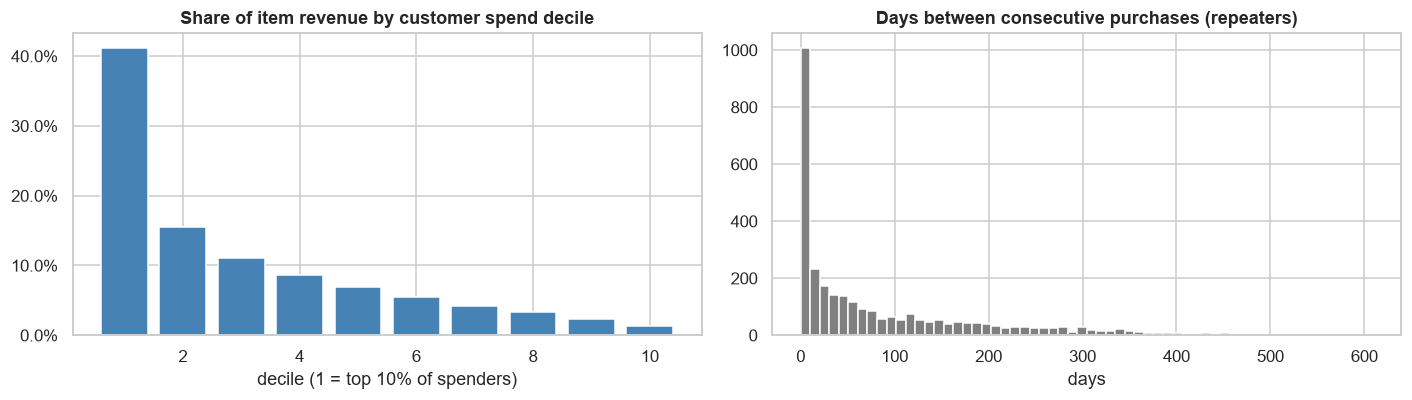

In [3]:
# monetary contribution by spend decile (persons with item revenue; ties split deterministically by rank)
spend = per_person["sum"].sort_values(ascending=False)
deciles = pd.Series(np.ceil(10 * np.arange(1, len(spend) + 1) / len(spend)).astype(int), index=spend.index)
dec = spend.groupby(deciles).agg(customers="size", revenue="sum", min_spend="min", max_spend="max")
dec["revenue_share"] = dec["revenue"] / dec["revenue"].sum()
dec["cumulative_share"] = dec["revenue_share"].cumsum()
dec["repeat_share"] = per_person.loc[spend.index, "size"].gt(1).groupby(deciles).mean()
dec.index.name = "spend decile (1 = top 10%)"
display(dec)

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].bar(dec.index, dec["revenue_share"], color="steelblue"); ax[0].yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax[0].set(title="Share of item revenue by customer spend decile", xlabel="decile (1 = top 10% of spenders)")
ax[1].hist(gaps, bins=60, color="gray"); ax[1].set(title="Days between consecutive purchases (repeaters)", xlabel="days")
plt.tight_layout(); plt.show()

**Interpretation.**
- **Scale:** 96,096 customers placed 99,441 orders, only **1.035 orders per customer**.
- **Repeat customers are rare:** 3.12% of customers, 6.38% of orders and 5.73% of item revenue. They spend about **1.9× as much** (259.87 vs 137.63 BRL per customer), but they're too few to matter much in aggregate.
- **Typical values:** the average order is 137.75 BRL (median 86.90), and average spend per customer is 142.44 BRL (median 89.90). Mean and median diverge because of the heavy tail described in notebook 05.
- **Time between purchases:** across 3,053 intervals between distinct purchase events (same-second orders merged, Q-09), the median is 38 days and the mean 86. 46% of repeat purchases come within 30 days, so repurchase, when it happens, tends to happen soon.
- **Concentration:** the top 10% of spenders generate **41.2% of item revenue** and the top 20% generate 56.8%; the bottom half generates 16.6%. The top decile is also where repeat buyers concentrate (8.7%, against 0.2% in the bottom decile).

## 2. RFM analysis
### 2.1 RFM values and scores (reused query `customer_rfm`)
- **Recency** = days from the last eligible purchase to the reference date.
- **Frequency** = the number of eligible orders.
- **Monetary** = item revenue of those orders.
- **Scores:** `1 + floor(5 · percent_rank)`, capped at 5, tie-aware. Recency is ranked so that more recent means a higher score.

The cell below **recomputes everything independently in pandas from Gold** and requires an exact match.

In [4]:
rfm = run_query("customer_rfm", engine=engine, params={"reference_date": REFERENCE_DATE, "order_scope": "delivered"})
rfm = rfm[rfm["has_eligible_purchase"]].copy()

# independent recomputation (delivered scope): items, purchased and delivered on or before the reference date
ref = pd.Timestamp(REFERENCE_DATE)
el = orders[orders["has_items"] & (orders["purchase_date"] <= ref) & (orders["order_status"] == "delivered")
            & (orders["order_delivered_customer_date"].dt.normalize() <= ref)]
mine = el.groupby("customer_unique_id").agg(last=("purchase_date", "max"), frequency=("order_id", "size"),
                                            monetary=("items_price_total", "sum"))
mine["recency_days"] = (ref - mine["last"]).dt.days
mine["monetary"] = mine["monetary"].round(2)          # money is cents: float noise (e.g. 39.900000000000006) must not break SQL ties

def score(s, ascending):
    r = s.rank(method="min", ascending=ascending)                       # tie-aware, like SQL percent_rank
    return np.minimum(5, 1 + np.floor(5 * (r - 1) / (len(s) - 1))).astype(int)

mine["r_score"], mine["f_score"], mine["m_score"] = score(-mine["recency_days"], True), score(mine["frequency"], True), score(mine["monetary"], True)
cmp = rfm.merge(mine.reset_index(), on="customer_unique_id", how="outer", suffixes=("", "_pd"), validate="1:1")
checks = {"same persons": len(cmp) == len(rfm) == len(mine),
          "recency": (cmp["recency_days"] == cmp["recency_days_pd"]).all(),
          "frequency": (cmp["frequency"] == cmp["frequency_pd"]).all(),
          "monetary": (cmp["monetary"].astype(float).round(2) == cmp["monetary_pd"].round(2)).all(),
          **{s: (cmp[s] == cmp[f"{s}_pd"]).all() for s in ("r_score", "f_score", "m_score")}}
checks = {k: bool(v) for k, v in checks.items()}
print(checks); assert all(checks.values())
print(f"RFM persons (eligible as of {REFERENCE_DATE}, delivered scope): {len(rfm):,}")
for s, col in (("r_score", "recency_days"), ("f_score", "frequency"), ("m_score", "monetary")):
    fmt = (lambda v: f"{v:,.2f}") if col == "monetary" else (lambda v: f"{v:,.0f}")
    print(f"  {s}: " + ", ".join(f"{int(k)}: {fmt(g[col].astype(float).min())} to {fmt(g[col].astype(float).max())} (n={len(g):,})"
                                for k, g in rfm.groupby(s)))

{'same persons': True, 'recency': True, 'frequency': True, 'monetary': True, 'r_score': True, 'f_score': True, 'm_score': True}
RFM persons (eligible as of 2018-08-31, delivered scope): 93,293
  r_score: 1: 384 to 715 (n=18,688), 2: 270 to 383 (n=18,700), 3: 179 to 269 (n=18,649), 4: 94 to 178 (n=18,663), 5: 2 to 93 (n=18,593)
  f_score: 1: 1 to 1 (n=90,494), 5: 2 to 15 (n=2,799)
  m_score: 1: 0.85 to 39.90 (n=19,333), 2: 39.91 to 69.90 (n=19,422), 3: 69.94 to 109.90 (n=17,440), 4: 109.95 to 179.90 (n=18,612), 5: 179.91 to 13,440.00 (n=18,486)


**Validation and score meaning.** The independent pandas recomputation matches the approved SQL query **exactly** for all 93,293 people: R, F, M and all three scores. It also exposed one detail: a float total such as 39.900000000000006 must be rounded to cents to reproduce SQL's exact ties.

| Score | Recency (days since last purchase) | Monetary (item revenue, BRL) |
|---|---|---|
| 5 | 2–93 | above about 179 |
| 4 | 94–178 | about 109–179 |
| 3 | 179–269 | about 69–109 |
| 2 | 270–383 | about 39–69 |
| 1 | 384–715 | up to about 39 |

**Frequency carries almost no gradation:** `f_score` is 1 for exactly one order (90,494 people) and 5 for two or more (2,799). There are no customers with scores 2–4. This is why the segments below treat repeat status as a yes/no attribute instead of a score.

### 2.2 Segment definitions
Frequency is effectively binary here (97% of people have one order, so `f_score` is 1 or 5). The classic 5 × 5 × 5 RFM label grids would therefore assign "loyalty" labels to one-time buyers. The segments below use **repeat status first**, then recency and monetary scores. Every person falls into exactly one segment.

| Segment | Rule | Meaning |
|---|---|---|
| **Champions** | 2+ orders, R ≥ 4, M ≥ 4 | repeat buyers who bought recently and spend the most |
| **Loyal Customers** | 2+ orders, R ≥ 3, not Champions | repeat buyers, still recent |
| **At Risk** | 2+ orders, R ≤ 2 | repeat buyers whose last purchase is old: valuable history, gone quiet |
| **Potential Loyalists** | 1 order, R ≥ 4 | recent first-time buyers: the realistic pool for a second purchase |
| **Needs Attention** | 1 order, R = 3 | first-time buyers of a few months ago |
| **Inactive** | 1 order, R ≤ 2 | one-time buyers with no purchase for many months |

**"Lost" is deliberately not used.** Inactivity can't confirm that a customer is gone (notebook 07), and for one-time buyers "not buying again" is the normal state, not a loss.

,customers,median_recency_days,mean_frequency,median_monetary,revenue,customer_share,revenue_share,revenue_per_customer
segment,,,,,,,,
Champions,930,89.000,2.189,238.845,"304,671.570",0.010,0.023,327.604
Loyal Customers,872,197.500,2.071,127.995,"174,417.150",0.009,0.013,200.020
At Risk,997,366.000,2.081,170.000,"248,766.510",0.011,0.019,249.515
Potential Loyalists,36057,94.000,1.000,89.000,"5,054,688.270",0.386,0.383,140.186
Needs Attention,18046,221.000,1.000,86.300,"2,345,842.810",0.193,0.178,129.992
Inactive,36391,384.000,1.000,85.000,"5,080,118.180",0.390,0.385,139.598


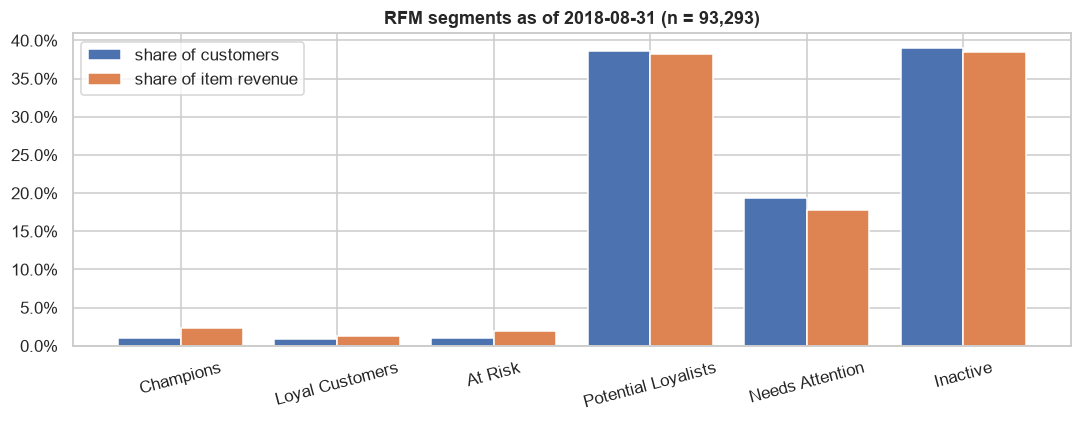

In [5]:
repeat = rfm["frequency"] >= 2
rules = {
    "Champions": repeat & (rfm["r_score"] >= 4) & (rfm["m_score"] >= 4),
    "Loyal Customers": repeat & (rfm["r_score"] >= 3) & ~((rfm["r_score"] >= 4) & (rfm["m_score"] >= 4)),
    "At Risk": repeat & (rfm["r_score"] <= 2),
    "Potential Loyalists": ~repeat & (rfm["r_score"] >= 4),
    "Needs Attention": ~repeat & (rfm["r_score"] == 3),
    "Inactive": ~repeat & (rfm["r_score"] <= 2),
}
membership = pd.DataFrame(rules)
assert (membership.sum(axis=1) == 1).all(), "segments must be exhaustive and mutually exclusive"
SEGMENTS = list(rules)
rfm["segment"] = pd.Categorical(membership.idxmax(axis=1), categories=SEGMENTS, ordered=True)
rfm["monetary"] = rfm["monetary"].astype(float)
prof = rfm.groupby("segment", observed=True).agg(customers=("customer_unique_id", "size"), median_recency_days=("recency_days", "median"),
                                                 mean_frequency=("frequency", "mean"), median_monetary=("monetary", "median"),
                                                 revenue=("monetary", "sum"))
prof["customer_share"] = prof["customers"] / prof["customers"].sum()
prof["revenue_share"] = prof["revenue"] / prof["revenue"].sum()
prof["revenue_per_customer"] = prof["revenue"] / prof["customers"]
display(prof)
assert prof["customers"].sum() == len(rfm) and np.isclose(prof["revenue"].sum(), rfm["monetary"].sum())

fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(prof))
ax.bar(x - .2, prof["customer_share"], .4, label="share of customers")
ax.bar(x + .2, prof["revenue_share"], .4, label="share of item revenue")
ax.set_xticks(x, prof.index, rotation=15); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.legend()
ax.set_title(f"RFM segments as of {REFERENCE_DATE} (n = {len(rfm):,})")
plt.tight_layout(); plt.savefig(FIG / "rfm_segments.png", bbox_inches="tight"); plt.show()

**Interpretation.**
- **The three repeat segments together are only 3.0% of customers and 5.5% of item revenue:**
  - **Champions:** 930 people (1.0%), the highest value per customer (328 BRL).
  - **Loyal Customers:** 872 people.
  - **At Risk:** 997 people. They're as numerous as the Champions and spend 250 BRL each, but their last purchase was a median of about one year ago.
- **The one-time segments split almost evenly by recency:** Potential Loyalists 38.6%, Needs Attention 19.3%, Inactive 39.0%. Each segment's revenue share closely matches its customer share, because the typical one-time order (about 85–89 BRL median) is the same in every recency group.

**Business meaning:**
- **The lever is the second purchase, not deeper loyalty.** The realistic target is **Potential Loyalists** (36,057 recent first-time buyers), for example with post-delivery follow-up or a time-limited offer while repurchase is most likely (notebook 07).
- **At Risk** is the only group with proven repeat behaviour that has gone quiet, which makes it a small but well-defined win-back list.
- **Inactive** buyers shouldn't be written off as "lost": for most of them a single purchase was the normal behaviour.

## 3. Historical customer lifetime value (CLV)
**Definition:** the item revenue a person generated from delivered orders up to the reference date, which is the RFM monetary value. It is realised revenue, not profit, because Gold has no cost or margin data.

**Why not predictive CLV:** probabilistic models (BG/NBD with Gamma-Gamma) estimate each person's future purchase rate from their *repeat* history. Here 97% of people have no repeat purchase in about 20 months, the overall repeat rate is 3%, and there's no margin data. Individual forecasts would mostly reproduce the population average, with wide uncertainty, and would look more precise than they are. Historical CLV, with clear concentration and group statistics, is the defensible scope.

persons 93,293 | total historical CLV 13,208,504.49 BRL | mean 141.58, median 89.70 | Gini 0.520
revenue share of the top spenders: {'top 1%': '11.5%', 'top 5%': '29.1%', 'top 10%': '41.1%', 'top 20%': '56.6%'}


,customers,repeat_share,median_clv,mean_orders
other 95%,88627,0.027,82.940,1.029
top 5% (high value),4666,0.085,649.000,1.118


segment mix of the top 5%: {'Inactive': 37.9, 'Potential Loyalists': 37.9, 'Needs Attention': 15.7, 'Champions': 4.2, 'At Risk': 2.8, 'Loyal Customers': 1.6}


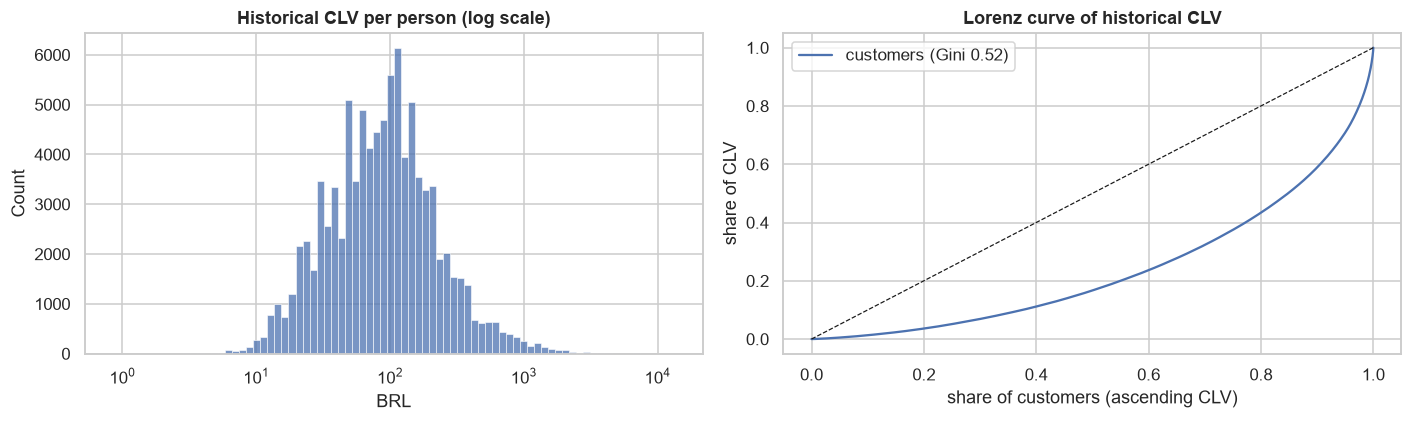

In [6]:
clv = rfm.set_index("customer_unique_id")["monetary"]
# validation: CLV aggregates = independent Gold sum of the same eligible orders; one value per person
assert clv.index.is_unique and np.isclose(clv.sum(), el["items_price_total"].sum())
lor = np.sort(clv.to_numpy()); cum = np.cumsum(lor) / lor.sum()
gini = 1 - 2 * np.trapezoid(np.concatenate([[0], cum]), np.linspace(0, 1, len(lor) + 1))
tops = {f"top {p}%": clv.nlargest(int(len(clv) * p / 100)).sum() / clv.sum() for p in (1, 5, 10, 20)}
print(f"persons {len(clv):,} | total historical CLV {clv.sum():,.2f} BRL | mean {clv.mean():.2f}, median {clv.median():.2f} | Gini {gini:.3f}")
print("revenue share of the top spenders:", {k: f"{v:.1%}" for k, v in tops.items()})

top = clv >= clv.quantile(.95)
hv = rfm.set_index("customer_unique_id").assign(high_value=top)
cmp_hv = hv.groupby("high_value").agg(customers=("frequency", "size"), repeat_share=("frequency", lambda f: (f > 1).mean()),
                                       median_clv=("monetary", "median"), mean_orders=("frequency", "mean"))
cmp_hv.index = ["other 95%", "top 5% (high value)"]
display(cmp_hv)
print("segment mix of the top 5%:", (hv.loc[top, "segment"].value_counts(normalize=True) * 100).round(1).to_dict())

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(clv, bins=80, log_scale=True, ax=ax[0]); ax[0].set(title="Historical CLV per person (log scale)", xlabel="BRL")
ax[1].plot(np.linspace(0, 1, len(lor) + 1), np.concatenate([[0], cum]), label=f"customers (Gini {gini:.2f})")
ax[1].plot([0, 1], [0, 1], "k--", lw=.8); ax[1].set(title="Lorenz curve of historical CLV", xlabel="share of customers (ascending CLV)",
                                                   ylabel="share of CLV"); ax[1].legend()
plt.tight_layout(); plt.savefig(FIG / "clv_concentration.png", bbox_inches="tight"); plt.show()

**Interpretation.**
- **Totals:** historical CLV adds up to 13.21 M BRL across 93,293 people. The mean is 141.58 BRL and the median 89.70. The aggregation matches an independent Gold sum of the same orders.
- **Concentration:** Gini 0.52. The **top 5% of customers hold 29.1% of value**, the top 10% hold 41.1%, and the top 1% hold 11.5%.
- **High-value customers are mostly big one-time buyers, not loyal ones.** The top 5% (CLV ≥ p95) have a median CLV of 649 BRL against 83 for everyone else, but only 8.5% of them are repeat buyers (2.7% elsewhere), averaging 1.12 orders. About 92% of them sit in the one-time segments, and 38% are already Inactive.
- **Implications:**
  - Value here is created by **basket size at the first purchase**, so the CLV upside comes from turning big first-time buyers into second-time buyers.
  - Ranking customers by historical CLV mostly ranks first-order size. Treat it as a description of past revenue, not a forecast of future value.

## 4. Summary

| Area | Result | Implication |
|---|---|---|
| Purchasing | 1.035 orders per customer; 3.12% repeat customers = 5.73% of item revenue; repeat buyers spend 1.9× | Growth comes from acquisition; retention is a small base |
| Timing | median 38 days between purchases; 46% within 30 days | The window for a second purchase is short |
| Concentration | top 10% of spenders = 41% of revenue; CLV Gini 0.52 | Large first baskets drive value |
| RFM (validated exactly against SQL) | frequency is binary (1 vs 2+), so segments use repeat status, then R and M | Classic "loyalty" grids don't fit this marketplace |
| Segments | Champions 930, Loyal 872, At Risk 997; Potential Loyalists 36,057; Needs Attention 18,046; Inactive 36,391 | Target recent first-time buyers; win back At Risk |
| CLV | 13.21 M BRL historical; top 5% = 29.1%; 92% of them are one-time buyers | Historical, revenue-based; predictive CLV isn't supported by the data |

**Limitations:**
- RFM and CLV are as of 2018-08-31, in the delivered scope, using current order status (Gold has no status history).
- Monetary values and CLV are revenue, not margin.
- Segment thresholds are analysis definitions documented above, not approved business KPIs.
- Recency for the earliest customers is limited by the data's start (2016-09).

In [7]:
engine.dispose()
rfm[["customer_unique_id", "recency_days", "frequency", "monetary", "r_score", "f_score", "m_score", "segment"]].head()

,customer_unique_id,recency_days,frequency,monetary,r_score,f_score,m_score,segment
0,0000366f3b9a7992bf8c76cfdf3221e2,113.000,1.000,129.900,4.000,1.000,4.000,Potential Loyalists
1,0000b849f77a49e4a4ce2b2a4ca5be3f,116.000,1.000,18.900,4.000,1.000,1.000,Potential Loyalists
2,0000f46a3911fa3c0805444483337064,539.000,1.000,69.000,1.000,1.000,2.000,Inactive
3,0000f6ccb0745a6a4b88665a16c9f078,323.000,1.000,25.990,2.000,1.000,1.000,Inactive
4,0004aac84e0df4da2b147fca70cf8255,290.000,1.000,180.000,2.000,1.000,5.000,Inactive
